# **Modelo de X-rays entrenado para diferenciar entre radiografías normales o con neumonía**

Francisco Ferrer López

In [ ]:
import os, shutil
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. **Visualización de los datos**

In [ ]:
#Descomprimimos el .zip
!mkdir -p /root/xray/
!unzip "/content/drive/MyDrive/Datos/Chest_X_ray.zip" -d "/root/"

Se han truncado las últimas 5000 líneas del flujo de salida.
  inflating: /root/chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: /root/chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: /root/chest_xray/tr

Es importante ver con cuantas imágenes estamos tratando, especialmente para ver la diferente cantidad de imágenes que hay en cada clase.

Al haber casi el triple de imágenes de neumonía que normales se tendrá que tomar en cuenta en los pesos para que no se vea afectado el modelo, dandole más importancia en este caso a las imágenes normales.

También se puede ver que en las carpetas de validation hay tan solo 18 imágenes en total, teniendo por tanto que tomar un % de train como validation para poder conseguir resultados con sentido.

Para no perder esas imágenes lo que se ha hecho es introducir las imágenes de validation en train.

In [ ]:
print('total training NORMAL images:', len(os.listdir('/root/chest_xray/chest_xray/train/NORMAL')))

total training NORMAL images: 1342


In [ ]:
print('total training PNEUMONIA images:', len(os.listdir('/root/chest_xray/chest_xray/train/PNEUMONIA')))

total training PNEUMONIA images: 3876


In [ ]:
print('total validation NORMAL images:', len(os.listdir('/root/chest_xray/chest_xray/val/NORMAL')))

total validation NORMAL images: 9


In [ ]:
print('total validation PNEUMONIA images:', len(os.listdir('/root/chest_xray/chest_xray/val/PNEUMONIA')))

total validation PNEUMONIA images: 9


In [ ]:
print('total test NORMAL images:', len(os.listdir('/root/chest_xray/chest_xray/test/NORMAL')))

total test NORMAL images: 234


In [ ]:
print('total test PNEUMONIA images:', len(os.listdir('/root/chest_xray/chest_xray/test/PNEUMONIA')))

total test PNEUMONIA images: 390


# 2. Data Augmentation y preparación de los datos

In [ ]:
#preparación de las imágenes en crudo

from tensorflow.keras.preprocessing.image import ImageDataGenerator

Primero de todo, para que nuestro modelo no vea varias veces la misma imágen distorsionaremos estas cuando se las demos, ya sea cambiandoles el tamaño, la rotación, el zoom.... De esta manera no se memorizará las imágenes.

Aquí introduciremos el validation_split de 0.2 como ya mencioné antes, cogiendo 20% de las imágenes de train para validation.

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,                     #esto se llama data augmentation
    width_shift_range=0.05,
    height_shift_range=0.05,       #todos estos datos y tal son para aleatoriedad, que si girar, cambiar tamaño...
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',   #esto es para rellenar las esquinas al girar con los pixeles cercanos para mantener lo que es
    validation_split=0.2  # reservar 20% de /train para validación
)
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
# usa el 80% del train
train_generator = train_datagen.flow_from_directory(   #usando flow from directory indicamos donde hacer el split anterior del train_datagen
        '/root/chest_xray/chest_xray/train',
        target_size = (224, 224),         # resize las fotos para que pueda entenderlas VGG16 lo hace automaticamente
        batch_size = 16,      #si nos fueramos a quedar cortos de memoria se podría disminuir el tamaño del batch (si las imagenes son muy grandes por ejemplo batch 1)
        class_mode = 'binary',
        subset = 'training',  # 80% para entrenar
        shuffle = True,  #para que no salgan primero todas las normales y después todas las de pneumonia
        seed = 42)  #seed sirve para saber qué imagenes elegir al separar el 80/20
#asignará 0 y 1 en función de la carpeta en la que se encuentren las imágenes por tanto binario

#después haré lo de separar por viral y bacterial

Found 4173 images belonging to 2 classes.


In [ ]:
#usa el 20% del train
validation_generator = train_datagen.flow_from_directory(
    '/root/chest_xray/chest_xray/train',
    target_size = (224, 224),
    batch_size = 16,
    class_mode = 'binary',
    subset = 'validation',  # 20% para validar
    shuffle = False, #si se mezclaran, las predicciones y las etiquetas reales no coincidirían
    seed = 42
)

Found 1043 images belonging to 2 classes.


In [ ]:
for data_batch, labels_batch in train_generator:
  print ('data batch shape:', data_batch.shape)
  print ('labels batch shape:', labels_batch.shape)
  break

#3 es para los colores RGB
#16 batch size
#224x224 size

#para labels 16 son el numero de ceros y unos

data batch shape: (16, 224, 224, 3)
labels batch shape: (16,)


In [ ]:
#importamos el VGG16
#cargamos los pesos sacados desde imagenet, include_top falso porque nosotros le daremos la información
#VGG16 necesita un tamaño fijo para que sus capas internas funcionen correctamente
#este tamaño es el que indicamos anteriormente de 224, 2244
from keras.applications import VGG16
conv_base = VGG16(weights = 'imagenet', include_top = False, input_shape = (224, 224, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#las capas del modelo VGG16

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#los nombres de las capas convolucionales para poder ver los nomres bien y poder copiarlos en la siguiente celda

for layer in conv_base.layers:
    if 'conv' in layer.name:
        print(layer.name)

block1_conv1
block1_conv2
block2_conv1
block2_conv2
block3_conv1
block3_conv2
block3_conv3
block4_conv1
block4_conv2
block4_conv3
block5_conv1
block5_conv2
block5_conv3


In [ ]:
#esto se hace para congelar todas las capas que no sean del bloque 5
#se congelan todas las que no sean del bloque 5 porque al ser la última es la que identifica patrones más complejos
#todas las anteriores identifican patrones más sencillos como líneas, no patrones de neumonía por ejemplo

conv_base.trainable = True
for layer in conv_base.layers:
  if layer.name == 'block5_conv1':
    layer.trainable = True
  elif layer.name == 'block5_conv2':
    layer.trainable = True
  elif layer.name == 'block5_conv3':
    layer.trainable = True
  else:
    layer.trainable = False

# 3. **Modelo**

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras import models
from keras import layers
from tensorflow.keras.layers import Dropout

In [ ]:
from keras import models
from keras import layers

model = models.Sequential()
model.add(conv_base)
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(Dropout(0.5))              #regularización para evitar overfitting
#Dense(1, sigmoid) para clasificación binaria
model.add(layers.Dense(1, activation='sigmoid'))

In [ ]:
#los pasos por los que pasan los datos en el modelo

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,137,729 (80.63 MB)

 Trainable params: 13,502,465 (51.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [ ]:
from tensorflow.keras import optimizers

#binary_crossentropy para clasificación binaria
model.compile (loss='binary_crossentropy', optimizer = optimizers.RMSprop(learning_rate=1e-4), metrics=['acc'])
#el rmsprop learning rate sirve para ajustar los pesos pero es muy pequeño
#porque no queremos destruir el modelo de vgg16, obviamente como ya está optimizado pues eso

In [ ]:
#class_weight para compensar el desbalance NORMAL vs PNEUMONIA
labels = train_generator.classes #los pasa a 0 normal y 1 pneumonia
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(labels), y=labels) #usa una formula que calcula en base a cuantas imagenes hay de cada tipo para darle el peso adecuado a cada una
#normal vale como 3 veces más, gracias a balanced por eso 0 es 1.93 y 1 0.67
class_weight_dict = dict(enumerate(class_weights))  #ennumerate hace simplemente que se vea como 0:1.94 y 1:0.67
print('class_weights:', class_weight_dict)

class_weights: {0: np.float64(1.9445479962721341), 1: np.float64(0.6730645161290323)}


En esta práctica, como dura tarda tanto tiempo en ejecutar, se implementan callbacks para hacerlo más eficiente.

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.callbacks import EarlyStopping

# guardamos el mejor modelo según val_acc
filepath = "/content/drive/MyDrive/ModelosPesos/chest_xray_weights.best.keras"               #guardar los pesos del mejor modelo
checkpoint = ModelCheckpoint(filepath, monitor='val_acc', verbose=1, save_best_only=True, mode='max')


# paramos si val_acc no mejora en 10 epochs
es = EarlyStopping(monitor='val_acc', patience=10)

callbacks_list = [checkpoint, es]

In [ ]:
history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator), #calcula cuantos steps segun los batches de 16 que hay en total, hay como 261
    epochs=30,  #30 epochs pero serán menos por el early stopping
    validation_data=validation_generator, #cubre todas las imágenes de train en cada epoch
    validation_steps=len(validation_generator),  #cubre todas las imágenes de validación
    class_weight=class_weight_dict,   #hay muchas más imagenes de pneumonias asi que con esto se dice que de la misma importancia a todas las clases como fue indicado en la celda anterior
    callbacks=callbacks_list,  #usa los callbacks indicados anteriormente
    verbose=1 #la barra progreso
)

Epoch 1/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - acc: 0.8760 - loss: 0.3562
Epoch 1: val_acc improved from None to 0.90988, saving model to /content/drive/MyDrive/ModelosPesos/chest_xray_weights.best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ModelosPesos/chest_xray_weights.best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 155s 546ms/step - acc: 0.9188 - loss: 0.2277 - val_acc: 0.9099 - val_loss: 0.2420
Epoch 2/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step - acc: 0.9575 - loss: 0.1606
Epoch 2: val_acc improved from 0.90988 to 0.91755, saving model to /content/drive/MyDrive/ModelosPesos/chest_xray_weights.best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ModelosPesos/chest_xray_weights.best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 122s 467ms/step - acc: 0.9573 - loss: 0.1455 - val_acc: 0.9175 - val_loss: 0.1666
Epoch 3/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - acc: 0.9674 - loss: 0.1054
Epoch 3: val_acc improved from 0.91755 to 0.94439, saving model 

# 4. **Conclusiones**

In [ ]:
print(history.history.keys())

dict_keys(['acc', 'loss', 'val_acc', 'val_loss'])


In [ ]:
import matplotlib.pyplot as plt

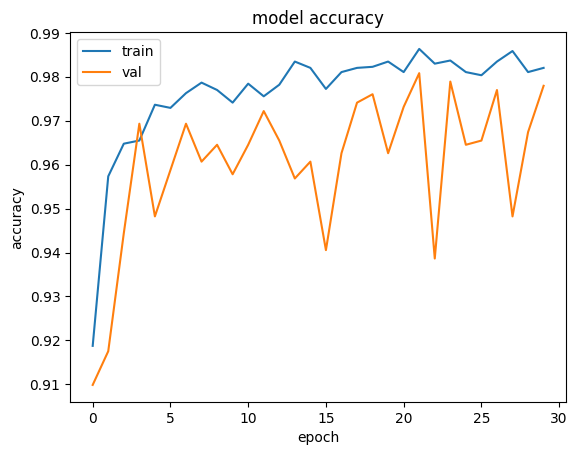

In [ ]:
plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','val'],loc ='upper left')
plt.show ()

La gráfica de accuracy muestra un aprendizaje estable sin overfitting,
ya que train y val se mantienen muy cercanas durante todo el entrenamiento.

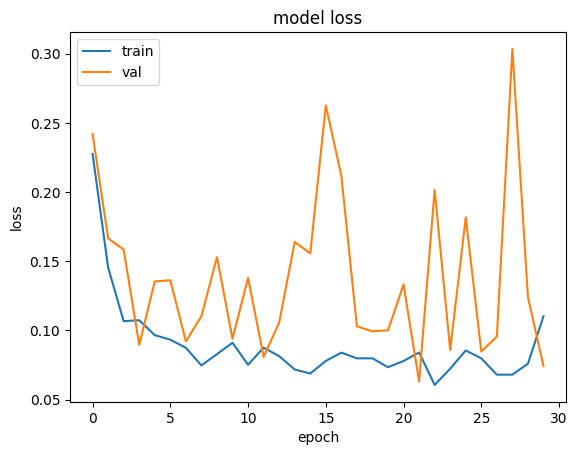

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','val'],loc ='upper left')
plt.show ()

En la loss se puede ver que val oscila bastante más que train, ya que las imagenes son más complejas y varían poco entre ellas.
El ModelCheckpoint guarda el mejor momento ignorando estos picos.

In [ ]:
test_generator = test_datagen.flow_from_directory(
    '/root/chest_xray/chest_xray/test',
    target_size = (224, 224),
    batch_size = 20,
    class_mode = 'binary',
    shuffle = False
)

Found 624 images belonging to 2 classes.


In [ ]:
#se carga el peso guardado con el callback para el test
model = tf.keras.models.load_model('/content/drive/MyDrive/ModelosPesos/chest_xray_weights.best.keras')

In [ ]:
scores = model.evaluate (test_generator)
print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))

32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 320ms/step - acc: 0.9247 - loss: 0.5756
compile_metrics: 92.47%


El 92.47% en test confirma que el modelo generaliza bien a imágenes nuevas.